<a href="https://colab.research.google.com/github/Symon-CNA/CNA/blob/main/PPC_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [31]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.animation import FuncAnimation
from IPython.display import HTML
import numpy as np
import matplotlib.pyplot as plt



# Parâmetros físicos iniciais de teste
alpha = 1.0e-5      # Difusividade térmica [m²/s]
k = 15.0            # Condutividade térmica [W/(m K)]
h = 100.0           # Coeficiente convectivo [W/(m² K)]

L = 0.05            # Comprimento característico [m]
T_initial = 500.0   # Temperatura inicial [K]
T_inf = 300.0       # Temperatura do fluido externo [K]

# Parâmetros numéricos
n_nodes = 51
dt = 1.0
t_final = 300.0

x = np.linspace(0, L, n_nodes)
dx = x[1] - x[0]

print(f"dx = {dx:.6e} m")
print(f"Número de nós = {n_nodes}")
print("\n")

def thomas_algorithm(lower, diag, upper, rhs):
    """
    Resolve um sistema tridiagonal usando o algoritmo de Thomas.

    lower: subdiagonal. Use lower[0] = 0.
    diag: diagonal principal.
    upper: superdiagonal. Use upper[-1] = 0.
    rhs: vetor do lado direito.

    Retorna:
        x: vetor solução.
    """

    n = len(diag)

    a = lower.copy()
    b = diag.copy()
    c = upper.copy()
    d = rhs.copy()

    # Eliminação progressiva
    for i in range(1, n):
        m = a[i] / b[i - 1]
        b[i] = b[i] - m * c[i - 1]
        d[i] = d[i] - m * d[i - 1]

    # Substituição regressiva
    x = np.zeros(n)
    x[-1] = d[-1] / b[-1]

    for i in range(n - 2, -1, -1):
        x[i] = (d[i] - c[i] * x[i + 1]) / b[i]

    return x


# Teste simples do algoritmo de Thomas
lower_test = np.array([0.0, -1.0, -1.0, -1.0])
diag_test = np.array([2.04, 2.04, 2.04, 2.04])
upper_test = np.array([-1.0, -1.0, -1.0, 0.0])
rhs_test = np.array([40.8, 0.8, 0.8, 200.8])

x_test = thomas_algorithm(lower_test, diag_test, upper_test, rhs_test)

print(x_test)


def build_implicit_system_no_generation(T_old, alpha, k, h, L, dt, T_inf):
    """
    Monta o sistema tridiagonal para o problema 1D transiente sem geração interna.

    Condições de contorno:
        x = 0 -> simetria adiabática
        x = L -> convecção
    """

    n = len(T_old)
    dx = L / (n - 1)

    r = alpha * dt / dx**2
    Bi_dx = h * dx / k

    lower = np.zeros(n)
    diag = np.zeros(n)
    upper = np.zeros(n)
    rhs = np.zeros(n)

    # Nó 0: simetria adiabática
    diag[0] = 1 + 2 * r
    upper[0] = -2 * r
    rhs[0] = T_old[0]

    # Nós internos
    for i in range(1, n - 1):
        lower[i] = -r
        diag[i] = 1 + 2 * r
        upper[i] = -r
        rhs[i] = T_old[i]

    # Nó final: convecção
    lower[-1] = -2 * r
    diag[-1] = 1 + 2 * r + 2 * r * Bi_dx
    upper[-1] = 0
    rhs[-1] = T_old[-1] + 2 * r * Bi_dx * T_inf

    return lower, diag, upper, rhs


def solve_heat_1d_no_generation(
    alpha,
    k,
    h,
    L,
    T_initial,
    T_inf,
    n_nodes,
    dt,
    t_final,
):
    """
    Resolve a condução transiente 1D sem geração interna usando:
        - diferenças finitas;
        - esquema implícito;
        - algoritmo de Thomas.
    """

    x = np.linspace(0, L, n_nodes)
    T = np.ones(n_nodes) * T_initial

    n_steps = int(t_final / dt)

    history = []
    times = []

    save_interval = max(1, n_steps // 30)

    for step in range(n_steps + 1):
        t = step * dt

        if step == 0 or step % save_interval == 0:
            history.append(T.copy())
            times.append(t)

        lower, diag, upper, rhs = build_implicit_system_no_generation(
            T_old=T,
            alpha=alpha,
            k=k,
            h=h,
            L=L,
            dt=dt,
            T_inf=T_inf,
        )

        T = thomas_algorithm(lower, diag, upper, rhs)

    return x, np.array(times), np.array(history), T


x, times, history, T_final = solve_heat_1d_no_generation(
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_nodes=n_nodes,
    dt=dt,
    t_final=t_final,
)

print("\n")
print("Temperatura final:")
print(T_final)


def find_lambda_roots(Bi, n_roots=30, tol=1e-12, max_iter=100):
    """
    Calcula as primeiras raízes positivas da equação:
        lambda * tan(lambda) = Bi

    As raízes estão nos intervalos:
        ((n-1)pi, (n-1/2)pi)
    para n = 1, 2, 3, ...
    """

    roots = []

    for n in range(1, n_roots + 1):
        a = (n - 1) * np.pi + 1e-9
        b = (n - 0.5) * np.pi - 1e-9

        def f(lam):
            return lam * np.tan(lam) - Bi

        fa = f(a)
        fb = f(b)

        # Bisseção
        for _ in range(max_iter):
            c = 0.5 * (a + b)
            fc = f(c)

            if abs(fc) < tol or abs(b - a) < tol:
                break

            if fa * fc < 0:
                b = c
                fb = fc
            else:
                a = c
                fa = fc

        roots.append(c)

    return np.array(roots)


def exact_solution_no_generation(x, t, alpha, k, h, L, T_initial, T_inf, n_terms=30):
    """
    Solução exata adimensional para a condução transiente 1D sem geração interna,
    com simetria adiabática em x=0 e convecção em x=L.
    """

    Bi = h * L / k
    Fo = alpha * t / L**2
    x_star = x / L

    lambdas = find_lambda_roots(Bi, n_roots=n_terms)

    theta = np.zeros_like(x_star, dtype=float)

    for lam in lambdas:
        coefficient = 4 * np.sin(lam) / (2 * lam + np.sin(2 * lam))
        theta += coefficient * np.cos(lam * x_star) * np.exp(-lam**2 * Fo)

    T_exact = T_inf + theta * (T_initial - T_inf)

    return T_exact



t_compare = t_final

T_exact_final = exact_solution_no_generation(
    x=x,
    t=t_compare,
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_terms=50,
)


def build_implicit_system_with_generation(
    T_old,
    alpha,
    k,
    h,
    L,
    dt,
    T_inf,
    rho,
    cp,
    q_dot,
):
    """
    Monta o sistema tridiagonal para o problema 1D transiente
    com geração interna.

    Condições de contorno:
        x = 0 -> simetria adiabática
        x = L -> convecção

    O algoritmo de Thomas será usado depois para resolver o sistema.
    """

    n = len(T_old)
    dx = L / (n - 1)

    r = alpha * dt / dx**2
    Bi_dx = h * dx / k

    # Incremento de temperatura associado à geração interna
    source_term = q_dot * dt / (rho * cp)

    lower = np.zeros(n)
    diag = np.zeros(n)
    upper = np.zeros(n)
    rhs = np.zeros(n)

    # Nó 0: simetria adiabática
    diag[0] = 1 + 2 * r
    upper[0] = -2 * r
    rhs[0] = T_old[0] + source_term

    # Nós internos
    for i in range(1, n - 1):
        lower[i] = -r
        diag[i] = 1 + 2 * r
        upper[i] = -r
        rhs[i] = T_old[i] + source_term

    # Nó final: convecção
    lower[-1] = -2 * r
    diag[-1] = 1 + 2 * r + 2 * r * Bi_dx
    upper[-1] = 0
    rhs[-1] = T_old[-1] + 2 * r * Bi_dx * T_inf + source_term

    return lower, diag, upper, rhs



def solve_heat_1d_with_generation(
    alpha,
    k,
    h,
    L,
    T_initial,
    T_inf,
    n_nodes,
    dt,
    t_final,
    rho,
    cp,
    q_dot,
):
    """
    Resolve a condução transiente 1D com geração interna usando:
        - diferenças finitas;
        - esquema implícito;
        - algoritmo de Thomas.
    """

    x = np.linspace(0, L, n_nodes)
    T = np.ones(n_nodes) * T_initial

    n_steps = int(t_final / dt)

    history = []
    times = []

    save_interval = max(1, n_steps // 30)

    for step in range(n_steps + 1):
        t = step * dt

        if step == 0 or step % save_interval == 0:
            history.append(T.copy())
            times.append(t)

        lower, diag, upper, rhs = build_implicit_system_with_generation(
            T_old=T,
            alpha=alpha,
            k=k,
            h=h,
            L=L,
            dt=dt,
            T_inf=T_inf,
            rho=rho,
            cp=cp,
            q_dot=q_dot,
        )

        T = thomas_algorithm(lower, diag, upper, rhs)

    return x, np.array(times), np.array(history), T



# Propriedades adicionais necessárias para o termo de geração
rho = 7800.0   # massa específica [kg/m³]
cp = 500.0     # calor específico [J/(kg K)]

# Solução sem geração, usando a função do item 1
x_no_gen, times_no_gen, history_no_gen, T_final_no_gen = solve_heat_1d_no_generation(
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_nodes=n_nodes,
    dt=dt,
    t_final=t_final,
)

# Solução com geração interna nula
x_q0, times_q0, history_q0, T_final_q0 = solve_heat_1d_with_generation(
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_nodes=n_nodes,
    dt=dt,
    t_final=t_final,
    rho=rho,
    cp=cp,
    q_dot=0.0,
)

max_diff_q0 = np.max(np.abs(T_final_q0 - T_final_no_gen))

print("\n")
print(f"Diferença máxima para q_dot = 0: {max_diff_q0:.6e} K")



q_dot_values = [1.0e-6, 1.0e-3, 1.0, 1.0e3]

for q_dot_test in q_dot_values:
    _, _, _, T_final_test = solve_heat_1d_with_generation(
        alpha=alpha,
        k=k,
        h=h,
        L=L,
        T_initial=T_initial,
        T_inf=T_inf,
        n_nodes=n_nodes,
        dt=dt,
        t_final=t_final,
        rho=rho,
        cp=cp,
        q_dot=q_dot_test,
    )

    max_diff = np.max(np.abs(T_final_test - T_final_no_gen))

    print("\n")
    print(f"q_dot = {q_dot_test:.1e} W/m³ -> diferença máxima = {max_diff:.6e} K")



q_dot_example = 2.0e6  # geração interna [W/m³]

x_gen, times_gen, history_gen, T_final_gen = solve_heat_1d_with_generation(
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_nodes=n_nodes,
    dt=dt,
    t_final=t_final,
    rho=rho,
    cp=cp,
    q_dot=q_dot_example,
)

print("\n")
print("Temperatura final com geração interna:")
print(T_final_gen)



rho_real = 10970.0       # massa específica do UO2 [kg/m³]
cp_real = 300.0          # calor específico aproximado [J/(kg K)]
k_real = 2.5             # condutividade térmica em alta temperatura [W/(m K)]

alpha_real = k_real / (rho_real * cp_real)

h_real = 10000.0         # coeficiente convectivo aproximado [W/(m² K)]

L_real = 0.004           # comprimento característico [m]

T_initial_real = 900.0   # temperatura inicial do combustível [K]
T_inf_real = 580.0       # temperatura do fluido externo [K]

q_dot_real = 5.0e7       # geração interna volumétrica [W/m³]

n_nodes_real = 81
dt_real = 0.02
t_final_real = 5.0

print("\n")
print(f"alpha_real = {alpha_real:.6e} m²/s")


# Estimativa ilustrativa da geração volumétrica a partir de uma potência linear
q_linear_example = 40_000.0  # potência linear ilustrativa [W/m]
R_example = 0.004            # raio efetivo [m]

q_dot_estimated = q_linear_example / (np.pi * R_example**2)

print("\n")
print(f"Geração volumétrica estimada = {q_dot_estimated:.3e} W/m³")
print(f"Geração volumétrica adotada no modelo = {q_dot_real:.3e} W/m³")

# Cenário realista simplificado - sem geração interna
x_real_no_gen, times_real_no_gen, history_real_no_gen, T_final_real_no_gen = solve_heat_1d_no_generation(
    alpha=alpha_real,
    k=k_real,
    h=h_real,
    L=L_real,
    T_initial=T_initial_real,
    T_inf=T_inf_real,
    n_nodes=n_nodes_real,
    dt=dt_real,
    t_final=t_final_real,
)

# Cenário realista simplificado - com geração interna

x_real_gen, times_real_gen, history_real_gen, T_final_real_gen = solve_heat_1d_with_generation(
    alpha=alpha_real,
    k=k_real,
    h=h_real,
    L=L_real,
    T_initial=T_initial_real,
    T_inf=T_inf_real,
    n_nodes=n_nodes_real,
    dt=dt_real,
    t_final=t_final_real,
    rho=rho_real,
    cp=cp_real,
    q_dot=q_dot_real,
)

print("\n")
print("Cenário realista calculado com sucesso.")
print(f"Sem geração: history_real_no_gen.shape = {history_real_no_gen.shape}")
print(f"Com geração: history_real_gen.shape = {history_real_gen.shape}")

dx = 1.000000e-03 m
Número de nós = 51


[ 65.96983437  93.77846211 124.53822833 159.47952369]


Temperatura final:
[446.40486086 446.39609461 446.36979691 446.32597092 446.26462188
 446.18575712 446.0893861  445.97552035 445.8441735  445.69536126
 445.52910147 445.34541401 445.14432089 444.92584616 444.69001599
 444.43685861 444.16640431 443.87868549 443.57373658 443.2515941
 442.9122966  442.5558847  442.18240109 441.79189046 441.38439957
 440.95997721 440.51867419 440.06054335 439.58563953 439.0940196
 438.58574242 438.06086884 437.5194617  436.96158584 436.38730804
 435.79669707 435.18982365 434.56676045 433.92758206 433.27236503
 432.60118782 431.91413078 431.2112762  430.49270824 429.75851295
 429.00877824 428.2435939  427.46305156 426.66724468 425.85626858
 425.03022037]


Diferença máxima para q_dot = 0: 0.000000e+00 K


q_dot = 1.0e-06 W/m³ -> diferença máxima = 7.526069e-11 K


q_dot = 1.0e-03 W/m³ -> diferença máxima = 6.762554e-08 K


q_dot = 1.0e+00 W/m³ -> diferença máxim

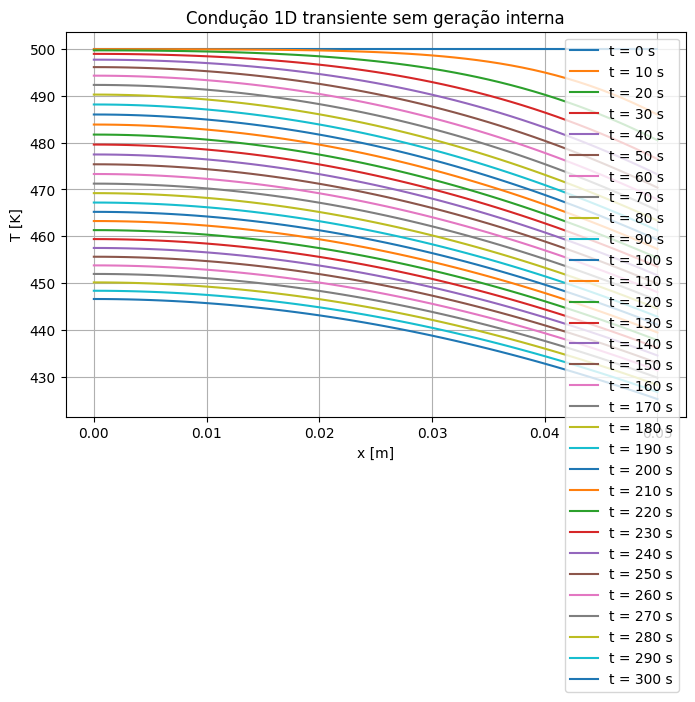

In [32]:
# Visualização dos perfis de Temperatura

plt.figure(figsize=(8, 5))

for i, t in enumerate(times):
    plt.plot(x, history[i], label=f"t = {t:.0f} s")

plt.xlabel("x [m]")
plt.ylabel("T [K]")
plt.title("Condução 1D transiente sem geração interna")
plt.legend()
plt.grid(True)
plt.show()

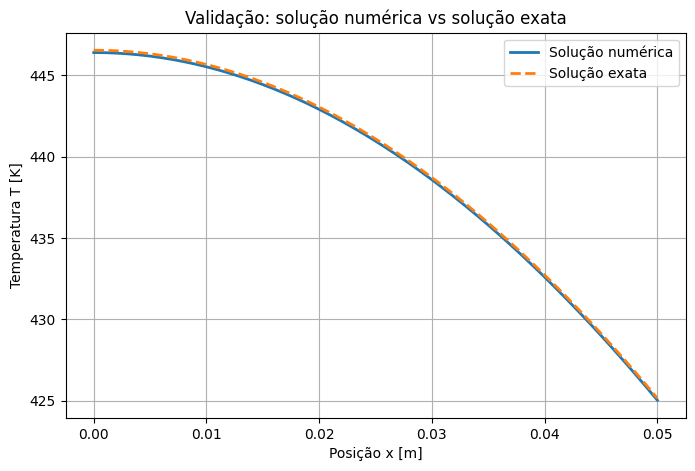

Erro máximo absoluto = 1.429686e-01 K
Erro médio absoluto = 1.359909e-01 K


In [33]:
# Comparação

t_compare = t_final

T_exact_final = exact_solution_no_generation(
    x=x,
    t=t_compare,
    alpha=alpha,
    k=k,
    h=h,
    L=L,
    T_initial=T_initial,
    T_inf=T_inf,
    n_terms=50,
)

plt.figure(figsize=(8, 5))

plt.plot(x, T_final, label="Solução numérica", linewidth=2)
plt.plot(x, T_exact_final, "--", label="Solução exata", linewidth=2)

plt.xlabel("Posição x [m]")
plt.ylabel("Temperatura T [K]")
plt.title("Validação: solução numérica vs solução exata")
plt.legend()
plt.grid(True)
plt.show()

erro_max = np.max(np.abs(T_final - T_exact_final))
erro_medio = np.mean(np.abs(T_final - T_exact_final))

print(f"Erro máximo absoluto = {erro_max:.6e} K")
print(f"Erro médio absoluto = {erro_medio:.6e} K")

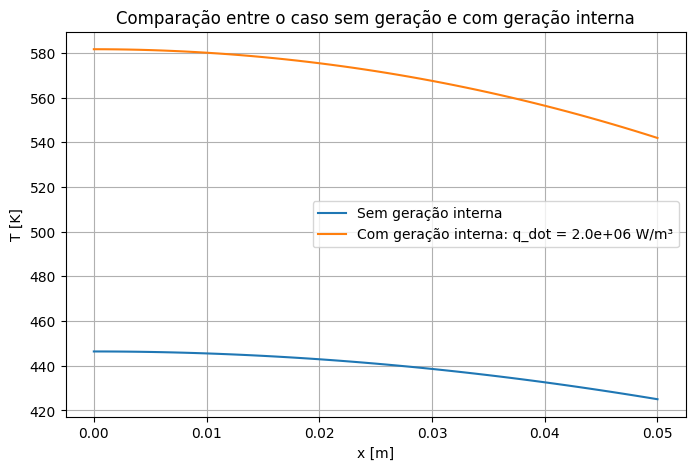

In [34]:
plt.figure(figsize=(8, 5))

plt.plot(x_no_gen, T_final_no_gen, label="Sem geração interna")
plt.plot(x_gen, T_final_gen, label=f"Com geração interna: q_dot = {q_dot_example:.1e} W/m³")

plt.xlabel("x [m]")
plt.ylabel("T [K]")
plt.title("Comparação entre o caso sem geração e com geração interna")
plt.legend()
plt.grid(True)
plt.show()

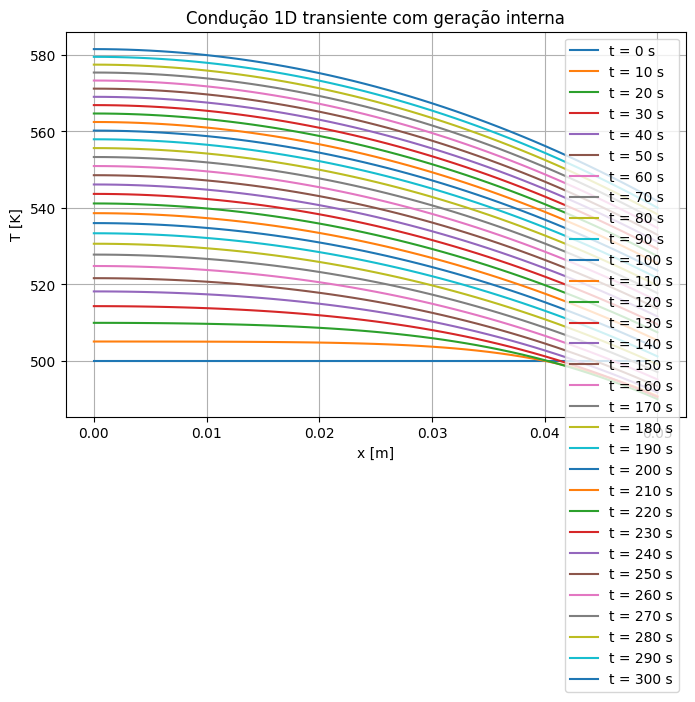

In [35]:
plt.figure(figsize=(8, 5))

for i, t in enumerate(times_gen):
    plt.plot(x_gen, history_gen[i], label=f"t = {t:.0f} s")

plt.xlabel("x [m]")
plt.ylabel("T [K]")
plt.title("Condução 1D transiente com geração interna")
plt.legend()
plt.grid(True)
plt.show()

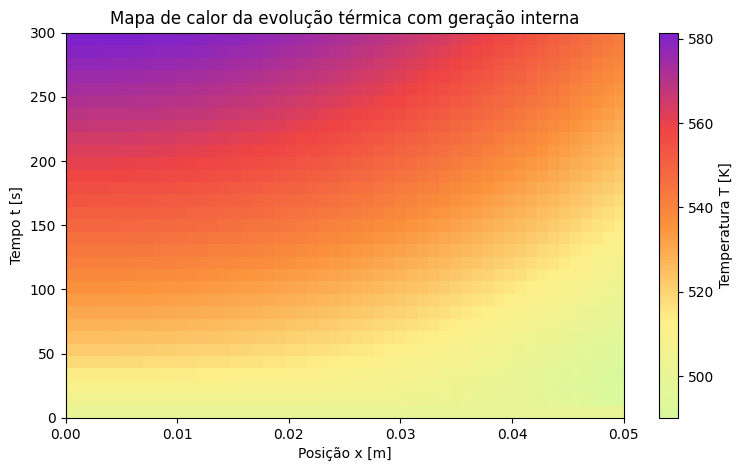

In [36]:
# Representações visuais da solução

from matplotlib.colors import LinearSegmentedColormap

# Escala personalizada:
# menor temperatura -> verde/amarelo claro
# temperatura intermediária -> laranja/vermelho
# maior temperatura -> roxo
thermal_cmap = LinearSegmentedColormap.from_list(
    "thermal_custom",
    [
        "#d9f99d",  # verde claro
        "#fef08a",  # amarelo claro
        "#fb923c",  # laranja
        "#ef4444",  # vermelho
        "#7e22ce"   # roxo
    ]
)

plt.figure(figsize=(9, 5))

plt.imshow(
    history_gen,
    aspect="auto",
    origin="lower",
    extent=[x_gen[0], x_gen[-1], times_gen[0], times_gen[-1]],
    cmap=thermal_cmap
)

plt.colorbar(label="Temperatura T [K]")
plt.xlabel("Posição x [m]")
plt.ylabel("Tempo t [s]")
plt.title("Mapa de calor da evolução térmica com geração interna")
plt.show()

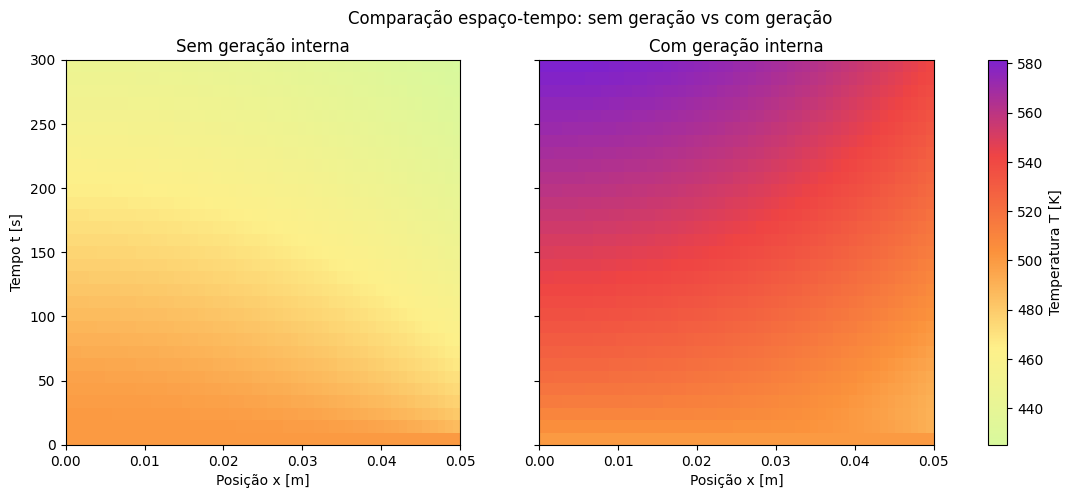

In [37]:
# Mapa de calor comparativo: sem geração vs com geração

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# Usa a mesma escala de cores nos dois gráficos
vmin = min(np.min(history_no_gen), np.min(history_gen))
vmax = max(np.max(history_no_gen), np.max(history_gen))

# Caso sem geração interna
img0 = axes[0].imshow(
    history_no_gen,
    aspect="auto",
    origin="lower",
    extent=[x_no_gen[0], x_no_gen[-1], times_no_gen[0], times_no_gen[-1]],
    cmap=thermal_cmap,
    vmin=vmin,
    vmax=vmax
)

axes[0].set_title("Sem geração interna")
axes[0].set_xlabel("Posição x [m]")
axes[0].set_ylabel("Tempo t [s]")

# Caso com geração interna
img1 = axes[1].imshow(
    history_gen,
    aspect="auto",
    origin="lower",
    extent=[x_gen[0], x_gen[-1], times_gen[0], times_gen[-1]],
    cmap=thermal_cmap,
    vmin=vmin,
    vmax=vmax
)

axes[1].set_title("Com geração interna")
axes[1].set_xlabel("Posição x [m]")

# Barra de cores comum aos dois gráficos
fig.colorbar(img1, ax=axes, label="Temperatura T [K]")

plt.suptitle("Comparação espaço-tempo: sem geração vs com geração")
plt.show()

In [38]:
# Animação comparativa da evolução temporal

# Número de quadros disponíveis nos dois casos
n_frames = min(len(times_no_gen), len(times_gen))

# Recorta os históricos para garantir o mesmo número de quadros
history_no_gen_anim = history_no_gen[:n_frames]
history_gen_anim = history_gen[:n_frames]

# Escala comum de temperatura para comparação justa
vmin_common = min(np.min(history_no_gen_anim), np.min(history_gen_anim))
vmax_common = max(np.max(history_no_gen_anim), np.max(history_gen_anim))

fig, axes = plt.subplots(2, 1, figsize=(10, 4), sharex=True)

# Cada faixa é uma matriz 1 x N
strip_no_gen = history_no_gen_anim[0][np.newaxis, :]
strip_gen = history_gen_anim[0][np.newaxis, :]

img0 = axes[0].imshow(
    strip_no_gen,
    aspect="auto",
    extent=[x_no_gen[0], x_no_gen[-1], 0, 1],
    cmap=thermal_cmap,
    vmin=vmin_common,
    vmax=vmax_common
)

img1 = axes[1].imshow(
    strip_gen,
    aspect="auto",
    extent=[x_gen[0], x_gen[-1], 0, 1],
    cmap=thermal_cmap,
    vmin=vmin_common,
    vmax=vmax_common
)

axes[0].set_title("Sem geração interna")
axes[1].set_title("Com geração interna")

for ax in axes:
    ax.set_yticks([])
    ax.set_ylabel("Corpo")
    ax.grid(False)

axes[1].set_xlabel("Posição x [m]")

# Barra de cores comum
fig.colorbar(img1, ax=axes, label="Temperatura T [K]")

time_text = fig.text(
    0.5,
    0.95,
    "",
    ha="center",
    va="center",
    fontsize=12
)

def update(frame):
    strip_no_gen = history_no_gen_anim[frame][np.newaxis, :]
    strip_gen = history_gen_anim[frame][np.newaxis, :]

    img0.set_data(strip_no_gen)
    img1.set_data(strip_gen)

    time_text.set_text(f"Distribuição térmica no corpo em t = {times_gen[frame]:.1f} s")

    return img0, img1, time_text

animation = FuncAnimation(
    fig,
    update,
    frames=n_frames,
    interval=250,
    blit=False
)

plt.close(fig)

HTML(animation.to_jshtml())

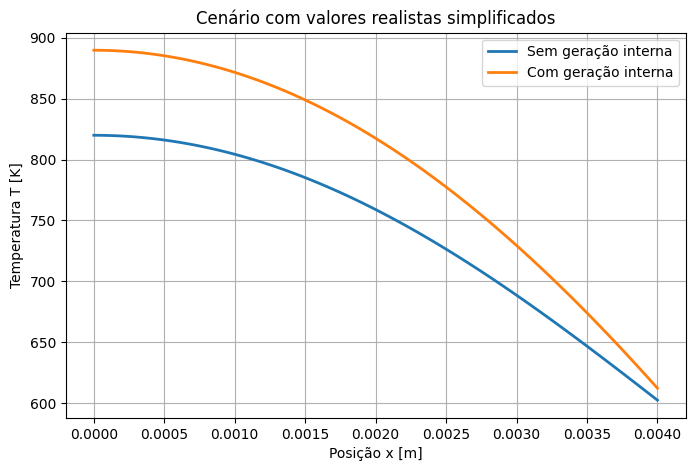

In [39]:
plt.figure(figsize=(8, 5))

plt.plot(
    x_real_no_gen,
    T_final_real_no_gen,
    label="Sem geração interna",
    linewidth=2
)

plt.plot(
    x_real_gen,
    T_final_real_gen,
    label="Com geração interna",
    linewidth=2
)

plt.xlabel("Posição x [m]")
plt.ylabel("Temperatura T [K]")
plt.title("Cenário com valores realistas simplificados")
plt.legend()
plt.grid(True)
plt.show()

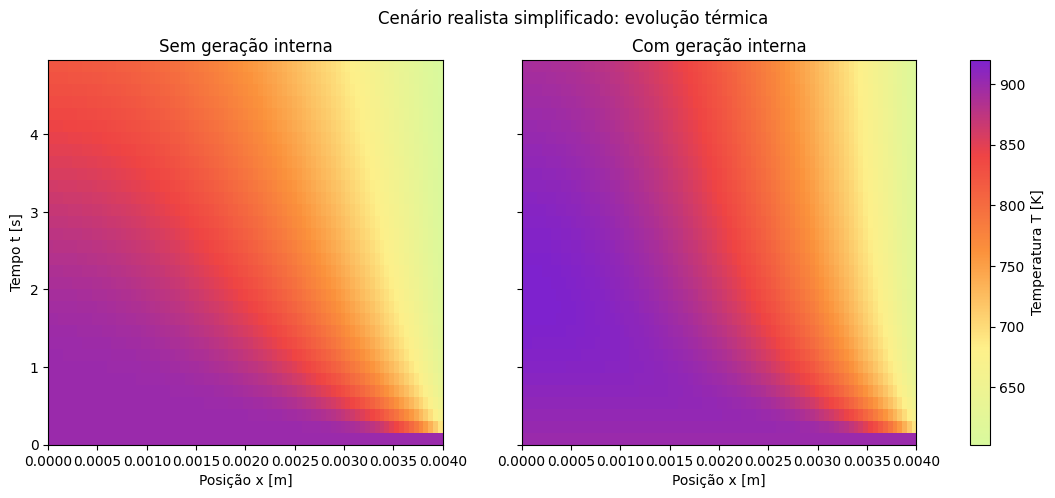

In [40]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

vmin_real = min(np.min(history_real_no_gen), np.min(history_real_gen))
vmax_real = max(np.max(history_real_no_gen), np.max(history_real_gen))

img0 = axes[0].imshow(
    history_real_no_gen,
    aspect="auto",
    origin="lower",
    extent=[
        x_real_no_gen[0],
        x_real_no_gen[-1],
        times_real_no_gen[0],
        times_real_no_gen[-1],
    ],
    cmap=thermal_cmap,
    vmin=vmin_real,
    vmax=vmax_real,
)

axes[0].set_title("Sem geração interna")
axes[0].set_xlabel("Posição x [m]")
axes[0].set_ylabel("Tempo t [s]")

img1 = axes[1].imshow(
    history_real_gen,
    aspect="auto",
    origin="lower",
    extent=[
        x_real_gen[0],
        x_real_gen[-1],
        times_real_gen[0],
        times_real_gen[-1],
    ],
    cmap=thermal_cmap,
    vmin=vmin_real,
    vmax=vmax_real,
)

axes[1].set_title("Com geração interna")
axes[1].set_xlabel("Posição x [m]")

fig.colorbar(img1, ax=axes, label="Temperatura T [K]")

plt.suptitle("Cenário realista simplificado: evolução térmica")
plt.show()